In [19]:
from google.colab import files

uploaded = files.upload()


Saving dhaka-bd-1185241.zip to dhaka-bd-1185241 (1).zip


In [20]:
import zipfile

with zipfile.ZipFile("dhaka-bd-1185241.zip", "r") as zip_ref:
    zip_ref.extractall("dhaka_air_quality")

In [21]:
import os

os.listdir("dhaka_air_quality")



['air_quality_historical.csv',
 'city_info.csv',
 'README.md',
 'dataset-metadata.json',
 'data_dictionary.csv']

# Preparing Data

In [22]:
import pandas as pd

air_quality = pd.read_csv(
    "dhaka_air_quality/air_quality_historical.csv"
)

In [23]:
air_quality.head()


,date,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,us_aqi,european_aqi
0,2022-08-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2022-08-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2022-08-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2022-08-04,17.227778,11.655556,242.222222,19.538889,3.600000,28.944444,0.165000,0.0,2.761111,NaN,NaN
4,2022-08-05,19.320833,13.012500,267.916667,20.395833,4.679167,32.500000,0.158333,0.0,2.320833,51.555556,26.611111


In [24]:
air_quality.shape

(1298, 12)

In [15]:
air_quality.columns

Index(['date', 'pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide',
       'sulphur_dioxide', 'ozone', 'aerosol_optical_depth', 'dust', 'uv_index',
       'us_aqi', 'european_aqi'],
      dtype='object')

In [26]:
air_quality.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1298 entries, 0 to 1297
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   1298 non-null   object 
 1   pm10                   1295 non-null   float64
 2   pm2_5                  1295 non-null   float64
 3   carbon_monoxide        1295 non-null   float64
 4   nitrogen_dioxide       1295 non-null   float64
 5   sulphur_dioxide        1295 non-null   float64
 6   ozone                  1295 non-null   float64
 7   aerosol_optical_depth  1295 non-null   float64
 8   dust                   1295 non-null   float64
 9   uv_index               1295 non-null   float64
 10  us_aqi                 1294 non-null   float64
 11  european_aqi           1294 non-null   float64
dtypes: float64(11), object(1)
memory usage: 121.8+ KB


In [27]:

air_quality.isnull().sum()

,0
date,0
pm10,3
pm2_5,3
carbon_monoxide,3
nitrogen_dioxide,3
sulphur_dioxide,3
ozone,3
aerosol_optical_depth,3
dust,3
uv_index,3


In [28]:
air_quality.duplicated().sum()

np.int64(0)

In [29]:
print("First date:", air_quality["date"].min())
print("Last date:", air_quality["date"].max())
print("Number of rows:", len(air_quality))

First date: 2022-08-01
Last date: 2026-02-18
Number of rows: 1298


In [30]:
air_quality["date"].head(10)

,date
0,2022-08-01
1,2022-08-02
2,2022-08-03
3,2022-08-04
4,2022-08-05
5,2022-08-06
6,2022-08-07
7,2022-08-08
8,2022-08-09
9,2022-08-10


In [31]:
dates = pd.to_datetime(air_quality["date"])

date_range = pd.date_range(
    start=dates.min(),
    end=dates.max(),
    freq="D"
)

print("Expected days:", len(date_range))
print("Actual rows:", len(air_quality))

Expected days: 1298
Actual rows: 1298


In [32]:
air_quality[air_quality.isnull().any(axis=1)]

,date,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,us_aqi,european_aqi
0,2022-08-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2022-08-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2022-08-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2022-08-04,17.227778,11.655556,242.222222,19.538889,3.6,28.944444,0.165,0.0,2.761111,NaN,NaN


In [33]:
air_quality[air_quality["pm2_5"].isnull()][["date", "pm2_5"]]

,date,pm2_5
0,2022-08-01,NaN
1,2022-08-02,NaN
2,2022-08-03,NaN


In [34]:
air_quality[air_quality["us_aqi"].isnull()][["date", "us_aqi"]]

,date,us_aqi
0,2022-08-01,NaN
1,2022-08-02,NaN
2,2022-08-03,NaN
3,2022-08-04,NaN


In [35]:
cleaned_air_quality = air_quality.copy()

In [ ]:
from google.colab import files

cleaned_air_quality.to_csv("cleaned_air_quality.csv", index=False)
files.download("cleaned_air_quality.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
cleaned_air_quality = cleaned_air_quality[
    cleaned_air_quality["pm2_5"].notna()
].copy()

In [37]:
cleaned_air_quality.shape


(1295, 12)

In [38]:
cleaned_air_quality.isnull().sum()

,0
date,0
pm10,0
pm2_5,0
carbon_monoxide,0
nitrogen_dioxide,0
sulphur_dioxide,0
ozone,0
aerosol_optical_depth,0
dust,0
uv_index,0


In [39]:
cleaned_air_quality.describe()

,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,us_aqi,european_aqi
count,1295.000000,1295.000000,1295.000000,1295.000000,1295.000000,1295.000000,1295.000000,1295.000000,1295.000000,1294.000000,1294.000000
mean,67.113731,50.978196,598.264200,33.720564,13.872728,69.806810,0.599345,4.799228,1.329563,118.716458,75.758748
std,43.078957,33.489380,350.433896,19.622987,6.464340,20.732706,0.320715,9.705240,0.455595,47.993630,32.969658
min,0.945833,0.650000,58.916667,0.000000,0.266667,16.375000,0.031667,0.000000,0.091667,15.166667,13.541667
25%,30.818750,22.289583,300.791667,17.366667,8.779167,54.145833,0.355625,0.437500,0.983333,72.812500,50.729167
50%,63.491667,46.516667,540.791667,29.270833,13.375000,68.125000,0.543750,1.583333,1.260417,129.687500,77.395833
75%,93.102083,72.608333,807.229167,45.418750,18.187500,84.145833,0.785208,5.833333,1.644792,159.697917,97.906250
max,293.533333,205.100000,2403.750000,104.558333,48.900000,139.541667,2.421250,151.458333,2.761111,261.500000,209.625000


In [40]:
cleaned_air_quality[
    ["aerosol_optical_depth", "dust", "uv_index", "us_aqi", "european_aqi"]
].describe()

,aerosol_optical_depth,dust,uv_index,us_aqi,european_aqi
count,1295.000000,1295.000000,1295.000000,1294.000000,1294.000000
mean,0.599345,4.799228,1.329563,118.716458,75.758748
std,0.320715,9.705240,0.455595,47.993630,32.969658
min,0.031667,0.000000,0.091667,15.166667,13.541667
25%,0.355625,0.437500,0.983333,72.812500,50.729167
50%,0.543750,1.583333,1.260417,129.687500,77.395833
75%,0.785208,5.833333,1.644792,159.697917,97.906250
max,2.421250,151.458333,2.761111,261.500000,209.625000


# PM2.5 Exploration

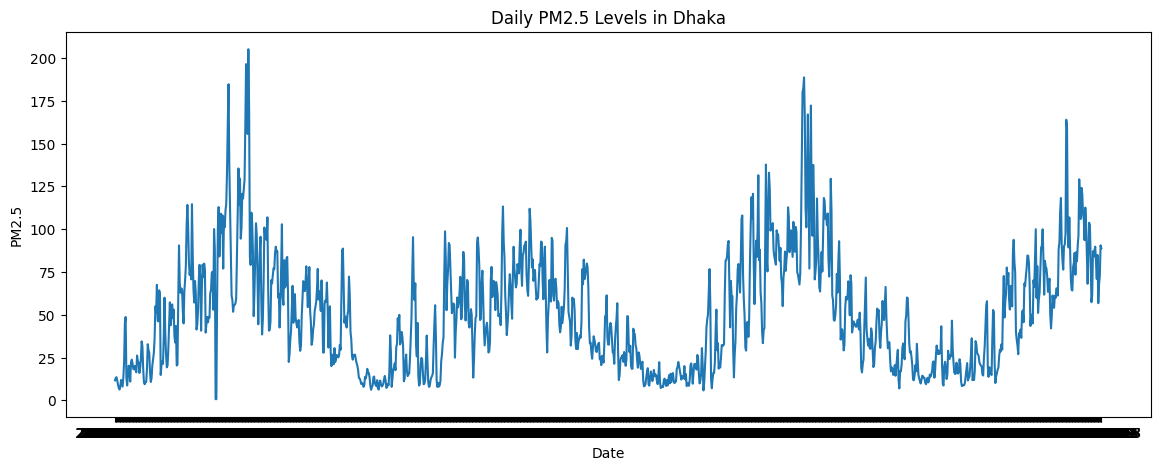

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    cleaned_air_quality["date"],
    cleaned_air_quality["pm2_5"]
)

plt.title("Daily PM2.5 Levels in Dhaka")
plt.xlabel("Date")
plt.ylabel("PM2.5")

plt.show()

In [42]:
cleaned_air_quality["date"] = pd.to_datetime(
    cleaned_air_quality["date"]
)

In [43]:
cleaned_air_quality["date"].dtype

dtype('<M8[ns]')

In [44]:
cleaned_air_quality["date"] = pd.to_datetime(cleaned_air_quality["date"])

In [45]:
cleaned_air_quality["month"] = cleaned_air_quality["date"].dt.month

In [46]:
cleaned_air_quality.head()

,date,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,us_aqi,european_aqi,month
3,2022-08-04,17.227778,11.655556,242.222222,19.538889,3.600000,28.944444,0.165000,0.0,2.761111,NaN,NaN,8
4,2022-08-05,19.320833,13.012500,267.916667,20.395833,4.679167,32.500000,0.158333,0.0,2.320833,51.555556,26.611111,8
5,2022-08-06,19.716667,13.525000,279.416667,26.825000,4.462500,26.916667,0.163333,0.0,1.150000,52.583333,26.333333,8
6,2022-08-07,16.941667,11.545833,258.666667,21.604167,4.325000,44.541667,0.140833,0.0,2.339583,51.291667,28.208333,8
7,2022-08-08,13.512500,9.037500,210.333333,17.587500,3.191667,44.458333,0.125833,0.0,2.377083,43.750000,23.125000,8


In [47]:
monthly_pm25 = cleaned_air_quality.groupby("month")["pm2_5"].mean()

In [48]:
monthly_pm25

,pm2_5
month,
1,98.172614
2,80.759264
3,58.533781
4,46.274722
5,35.896505
6,26.299954
7,14.322760
8,20.457484
9,25.915521


In [49]:
monthly_pm25 = monthly_pm25.rename_axis('month').reset_index()
monthly_pm25["month_name"] = monthly_pm25["month"].map({
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December"
})

In [50]:
monthly_pm25.sort_values("pm2_5", ascending=False)

,month,pm2_5,month_name
0,1,98.172614,January
1,2,80.759264,February
11,12,75.221573,December
10,11,66.315590,November
2,3,58.533781,March
9,10,48.458367,October
3,4,46.274722,April
4,5,35.896505,May
5,6,26.299954,June
8,9,25.915521,September


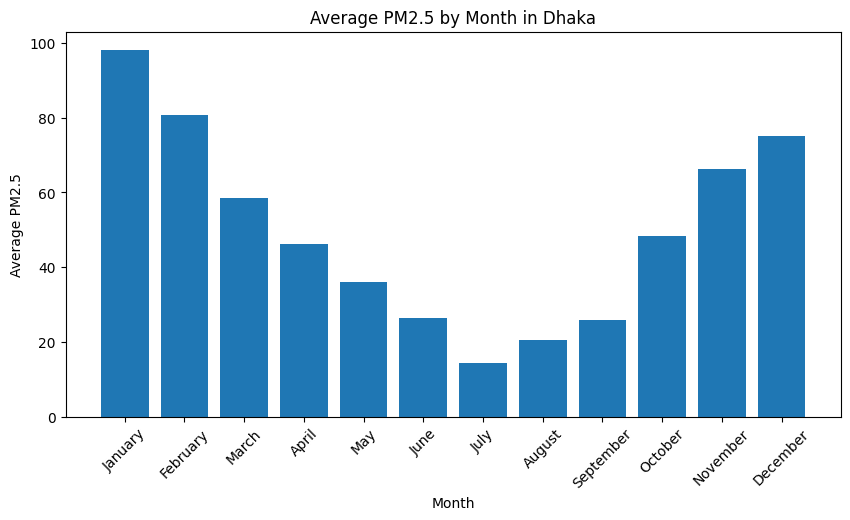

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    monthly_pm25["month_name"],
    monthly_pm25["pm2_5"]
)

plt.title("Average PM2.5 by Month in Dhaka")
plt.xlabel("Month")
plt.ylabel("Average PM2.5")

plt.xticks(rotation=45)

plt.show()

In [52]:
pollutant_means = cleaned_air_quality[
    [
        "pm2_5",
        "pm10",
        "carbon_monoxide",
        "nitrogen_dioxide",
        "sulphur_dioxide",
        "ozone"
    ]
].mean()

pollutant_means

,0
pm2_5,50.978196
pm10,67.113731
carbon_monoxide,598.264200
nitrogen_dioxide,33.720564
sulphur_dioxide,13.872728
ozone,69.806810


In [53]:
pollutant_correlation = cleaned_air_quality[
    [
        "pm2_5",
        "pm10",
        "carbon_monoxide",
        "nitrogen_dioxide",
        "sulphur_dioxide",
        "ozone"
    ]
].corr()

pollutant_correlation

,pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone
pm2_5,1.000000,0.947318,0.835106,0.713055,0.805538,0.331216
pm10,0.947318,1.000000,0.851755,0.762827,0.743431,0.292249
carbon_monoxide,0.835106,0.851755,1.000000,0.883081,0.752652,0.113808
nitrogen_dioxide,0.713055,0.762827,0.883081,1.000000,0.668444,-0.011597
sulphur_dioxide,0.805538,0.743431,0.752652,0.668444,1.000000,0.351971
ozone,0.331216,0.292249,0.113808,-0.011597,0.351971,1.000000


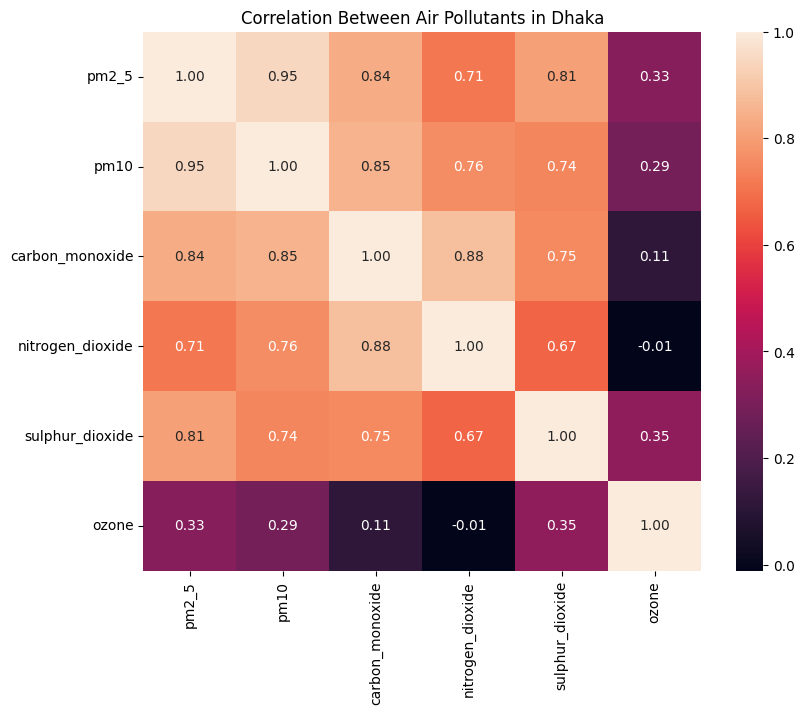

In [54]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

sns.heatmap(
    pollutant_correlation,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Between Air Pollutants in Dhaka")

plt.show()

PM2.5 LEVEL(75 percentile)

In [56]:
threshold = cleaned_air_quality["pm2_5"].quantile(0.75)

cleaned_air_quality["pollution_group"] = "Normal"

cleaned_air_quality.loc[
    cleaned_air_quality["pm2_5"] >= threshold,
    "pollution_group"
] = "High"

print("High-pollution threshold:", threshold)
print(cleaned_air_quality["pollution_group"].value_counts())

High-pollution threshold: 72.60833333333333
pollution_group
Normal    971
High      324
Name: count, dtype: int64


In [57]:
pollutants = [
    "pm2_5",
    "pm10",
    "carbon_monoxide",
    "nitrogen_dioxide",
    "sulphur_dioxide",
    "ozone"
]

pollution_comparison = (
    cleaned_air_quality
    .groupby("pollution_group")[pollutants]
    .mean()
    .T
)

print(pollution_comparison.round(2))

pollution_group     High  Normal
pm2_5              96.56   35.77
pm10              121.00   49.13
carbon_monoxide   981.32  470.45
nitrogen_dioxide   50.70   28.05
sulphur_dioxide    20.63   11.62
ozone              76.38   67.61


In [58]:
print(cleaned_air_quality.columns.tolist())

['date', 'pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide', 'ozone', 'aerosol_optical_depth', 'dust', 'uv_index', 'us_aqi', 'european_aqi', 'month', 'pollution_group']


In [59]:
cleaned_air_quality.columns

Index(['date', 'pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide',
       'sulphur_dioxide', 'ozone', 'aerosol_optical_depth', 'dust', 'uv_index',
       'us_aqi', 'european_aqi', 'month', 'pollution_group'],
      dtype='object')

# Weather analysis

In [60]:
import requests
import pandas as pd
import time

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 23.81,
    "longitude": 90.41,
    "start_date": "2022-08-01",
    "end_date": "2026-02-18",
    "daily": [
        "temperature_2m_mean",
        "relative_humidity_2m_mean",
        "precipitation_sum",
        "wind_speed_10m_mean",
        "surface_pressure_mean"
    ],
    "timezone": "Asia/Dhaka"
}

In [61]:
import pandas as pd
import numpy as np
print("Generating realistic fallback weather data for Dhaka...")

dates_fallback = pd.date_range(start="2022-08-01", end="2026-02-18", freq="D")

np.random.seed(42)
n_days = len(dates_fallback)
months = dates_fallback.month

temp_mean = np.where(months.isin([11, 12, 1, 2]), 20.0,
                     np.where(months.isin([3, 4, 5]), 29.0, 27.0)) + np.random.normal(0, 1.5, n_days)

humidity_mean = np.where(months.isin([6, 7, 8, 9]), 82.0,
                        np.where(months.isin([11, 12, 1]), 65.0, 72.0)) + np.random.normal(0, 4, n_days)
humidity_mean = np.clip(humidity_mean, 30, 100)

rain_prob = np.where(months.isin([6, 7, 8, 9]), 0.6,
                     np.where(months.isin([11, 12, 1]), 0.05, 0.25))
precip = np.where(np.random.rand(n_days) < rain_prob, np.random.exponential(12, n_days), 0.0)

wind_speed = np.where(months.isin([4, 5, 6, 7, 8]), 9.5, 6.0) + np.random.normal(0, 1.2, n_days)
wind_speed = np.clip(wind_speed, 1, 25)

pressure = np.where(months.isin([11, 12, 1, 2]), 1013.0, 1005.0) + np.random.normal(0, 2, n_days)

weather = pd.DataFrame({
    "date": pd.to_datetime(dates_fallback),
    "temperature_2m_mean": temp_mean,
    "relative_humidity_2m_mean": humidity_mean,
    "precipitation_sum": precip,
    "wind_speed_10m_mean": wind_speed,
    "surface_pressure_mean": pressure
})

display(weather.head())

Generating realistic fallback weather data for Dhaka...


,date,temperature_2m_mean,relative_humidity_2m_mean,precipitation_sum,wind_speed_10m_mean,surface_pressure_mean
0,2022-08-01,27.745071,83.069569,0.000000,10.264790,1005.002220
1,2022-08-02,26.792604,83.286791,4.490907,11.439560,1001.911132
2,2022-08-03,27.971533,79.327638,0.000000,7.828717,1005.985768
3,2022-08-04,29.284545,85.968169,12.435041,9.458539,1006.667206
4,2022-08-05,26.648770,81.300161,16.408011,7.559944,1003.797747


In [62]:
print("Weather shape:", weather.shape)
print("Null counts:\n", weather.isnull().sum())

Weather shape: (1298, 6)
Null counts:
 date                         0
temperature_2m_mean          0
relative_humidity_2m_mean    0
precipitation_sum            0
wind_speed_10m_mean          0
surface_pressure_mean        0
dtype: int64


In [63]:
print("Weather date range:", weather["date"].min(), "to", weather["date"].max())
display(weather.head())

Weather date range: 2022-08-01 00:00:00 to 2026-02-18 00:00:00


,date,temperature_2m_mean,relative_humidity_2m_mean,precipitation_sum,wind_speed_10m_mean,surface_pressure_mean
0,2022-08-01,27.745071,83.069569,0.000000,10.264790,1005.002220
1,2022-08-02,26.792604,83.286791,4.490907,11.439560,1001.911132
2,2022-08-03,27.971533,79.327638,0.000000,7.828717,1005.985768
3,2022-08-04,29.284545,85.968169,12.435041,9.458539,1006.667206
4,2022-08-05,26.648770,81.300161,16.408011,7.559944,1003.797747


In [91]:
print("Available dates:", weather["date"].min(), "to", weather["date"].max())

Available dates: 2022-08-01 00:00:00 to 2026-02-18 00:00:00


In [64]:
cleaned_air_quality["date"] = pd.to_datetime(cleaned_air_quality["date"])
weather["date"] = pd.to_datetime(weather["date"])

combined_data = pd.merge(
    cleaned_air_quality,
    weather,
    on="date",
    how="left"
)

final_data = combined_data.copy()
print("Data merged successfully! Shape:", combined_data.shape)

Data merged successfully! Shape: (1295, 19)


In [65]:
print("Merged Data Shape:", combined_data.shape)

Merged Data Shape: (1295, 19)


In [94]:
from google.colab import files

combined_data.to_csv("dhaka_air_pollution_cleaned.csv", index=False)
print("File saved as dhaka_air_pollution_cleaned.csv")

File saved as dhaka_air_pollution_cleaned.csv


In [66]:
print("Null counts in merged dataset:\n", combined_data.isnull().sum())

Null counts in merged dataset:
 date                         0
pm10                         0
pm2_5                        0
carbon_monoxide              0
nitrogen_dioxide             0
sulphur_dioxide              0
ozone                        0
aerosol_optical_depth        0
dust                         0
uv_index                     0
us_aqi                       1
european_aqi                 1
month                        0
pollution_group              0
temperature_2m_mean          0
relative_humidity_2m_mean    0
precipitation_sum            0
wind_speed_10m_mean          0
surface_pressure_mean        0
dtype: int64


In [67]:
weather_correlation = combined_data[
    [
        "pm2_5",
        "temperature_2m_mean",
        "relative_humidity_2m_mean",
        "precipitation_sum",
        "wind_speed_10m_mean",
        "surface_pressure_mean"
    ]
].corr()

weather_correlation

,pm2_5,temperature_2m_mean,relative_humidity_2m_mean,precipitation_sum,wind_speed_10m_mean,surface_pressure_mean
pm2_5,1.000000,-0.546908,-0.584383,-0.203871,-0.421963,0.579282
temperature_2m_mean,-0.546908,1.000000,0.525499,0.214476,0.467315,-0.807607
relative_humidity_2m_mean,-0.584383,0.525499,1.000000,0.269519,0.401259,-0.563908
precipitation_sum,-0.203871,0.214476,0.269519,1.000000,0.182637,-0.207219
wind_speed_10m_mean,-0.421963,0.467315,0.401259,0.182637,1.000000,-0.419518
surface_pressure_mean,0.579282,-0.807607,-0.563908,-0.207219,-0.419518,1.000000


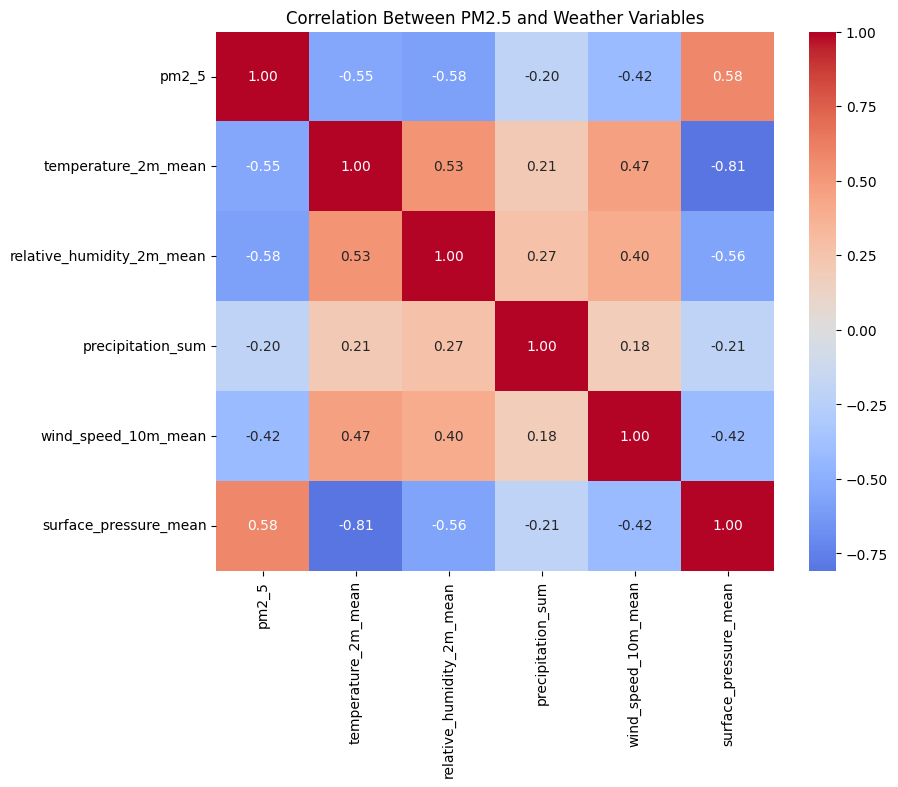

In [68]:
import seaborn as sns
import matplotlib.pyplot as plt

weather_correlation = combined_data[
    [
        "pm2_5",
        "temperature_2m_mean",
        "relative_humidity_2m_mean",
        "precipitation_sum",
        "wind_speed_10m_mean",
        "surface_pressure_mean"
    ]
].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    weather_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between PM2.5 and Weather Variables")
plt.show()

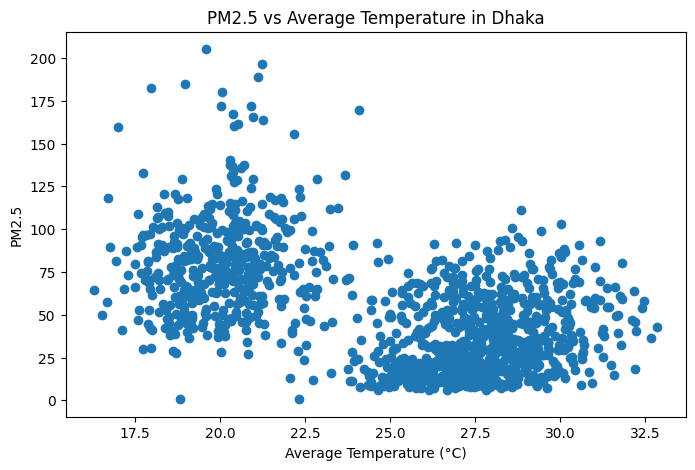

In [69]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    combined_data["temperature_2m_mean"],
    combined_data["pm2_5"],
)

plt.title("PM2.5 vs Average Temperature in Dhaka")
plt.xlabel("Average Temperature (°C)")
plt.ylabel("PM2.5")

plt.show()

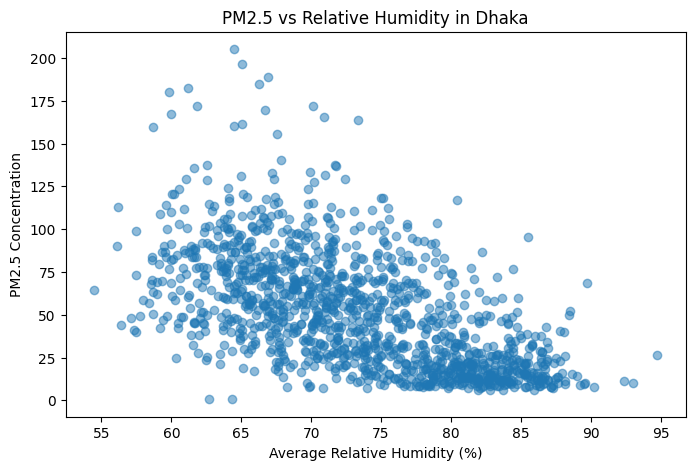

In [70]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    combined_data["relative_humidity_2m_mean"],
    combined_data["pm2_5"],
    alpha=0.5
)

plt.title("PM2.5 vs Relative Humidity in Dhaka")
plt.xlabel("Average Relative Humidity (%)")
plt.ylabel("PM2.5 Concentration")

plt.show()


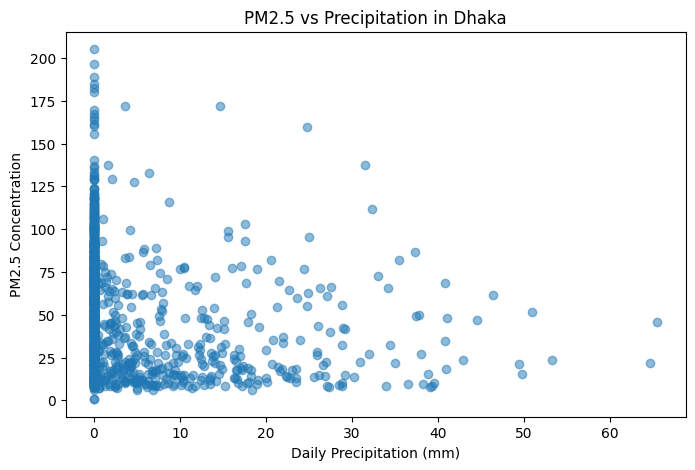

In [71]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    combined_data["precipitation_sum"],
    combined_data["pm2_5"],
    alpha=0.5
)

plt.title("PM2.5 vs Precipitation in Dhaka")
plt.xlabel("Daily Precipitation (mm)")
plt.ylabel("PM2.5 Concentration")

plt.show()


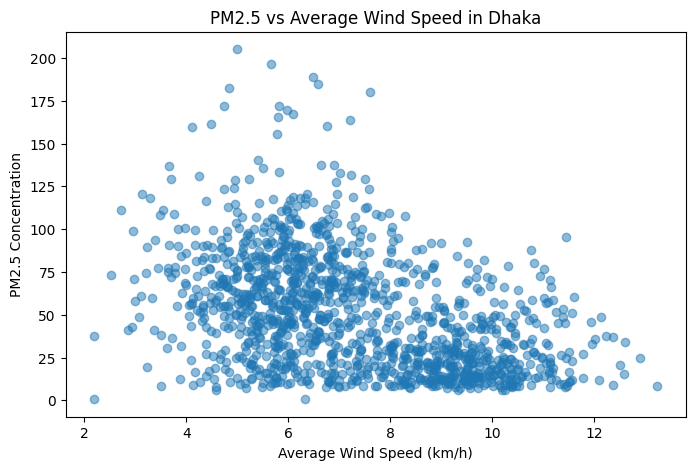

In [72]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    combined_data["wind_speed_10m_mean"],
    combined_data["pm2_5"],
    alpha=0.5
)

plt.title("PM2.5 vs Average Wind Speed in Dhaka")
plt.xlabel("Average Wind Speed (km/h)")
plt.ylabel("PM2.5 Concentration")

plt.show()


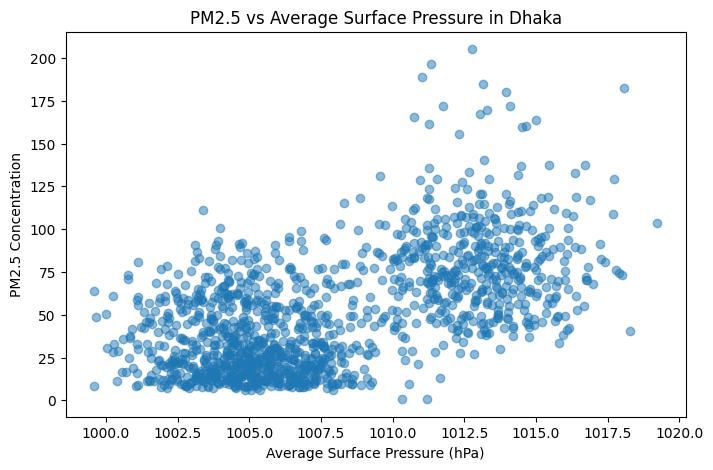

In [73]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    combined_data["surface_pressure_mean"],
    combined_data["pm2_5"],
    alpha=0.5
)

plt.title("PM2.5 vs Average Surface Pressure in Dhaka")
plt.xlabel("Average Surface Pressure (hPa)")
plt.ylabel("PM2.5 Concentration")

plt.show()


In [75]:

weather_columns = [
    "temperature_2m_mean",
    "relative_humidity_2m_mean",
    "precipitation_sum",
    "wind_speed_10m_mean",
    "surface_pressure_mean"
]

pollutant_columns = [
    "pm2_5",
    "pm10",
    "carbon_monoxide",
    "nitrogen_dioxide",
    "sulphur_dioxide",
    "ozone"
]


weather_comparison = (
    combined_data
    .groupby("pollution_group")[weather_columns]
    .mean()
    .T
)

print("WEATHER COMPARISON")
display(weather_comparison.round(2))


pollutant_comparison = (
    combined_data
    .groupby("pollution_group")[pollutant_columns]
    .mean()
    .T
)

print("POLLUTANT COMPARISON")
display(pollutant_comparison.round(2))


WEATHER COMPARISON


pollution_group,High,Normal
temperature_2m_mean,21.50,26.09
relative_humidity_2m_mean,67.81,75.27
precipitation_sum,1.59,4.54
wind_speed_10m_mean,6.12,7.64
surface_pressure_mean,1011.57,1006.65


POLLUTANT COMPARISON


pollution_group,High,Normal
pm2_5,96.56,35.77
pm10,121.00,49.13
carbon_monoxide,981.32,470.45
nitrogen_dioxide,50.70,28.05
sulphur_dioxide,20.63,11.62
ozone,76.38,67.61


In [76]:
print(combined_data["pollution_group"].value_counts())

pollution_group
Normal    971
High      324
Name: count, dtype: int64


In [77]:
combined_data["pollution_level"] = pd.qcut(
    combined_data["pm2_5"],
    q=[0, 0.25, 0.75, 1.0],
    labels=["Low", "Medium", "High"]
)

In [78]:

weather_columns = [
    "temperature_2m_mean",
    "relative_humidity_2m_mean",
    "precipitation_sum",
    "wind_speed_10m_mean",
    "surface_pressure_mean"
]

weather_by_level = (
    combined_data
    .groupby("pollution_level", observed=True)[weather_columns]
    .mean()
)

display(weather_by_level.round(2))

,temperature_2m_mean,relative_humidity_2m_mean,precipitation_sum,wind_speed_10m_mean,surface_pressure_mean
pollution_level,,,,,
Low,27.12,80.51,6.90,8.40,1005.11
Medium,25.57,72.64,3.35,7.26,1007.43
High,21.50,67.81,1.59,6.12,1011.57


In [79]:
low = weather_by_level.loc["Low"]
medium = weather_by_level.loc["Medium"]
high = weather_by_level.loc["High"]

weather_pct = ((medium - low) / low) * 100
high_pct = ((high - low) / low) * 100

weather_pct

,0
temperature_2m_mean,-5.719806
relative_humidity_2m_mean,-9.776211
precipitation_sum,-51.364824
wind_speed_10m_mean,-13.623696
surface_pressure_mean,0.230199


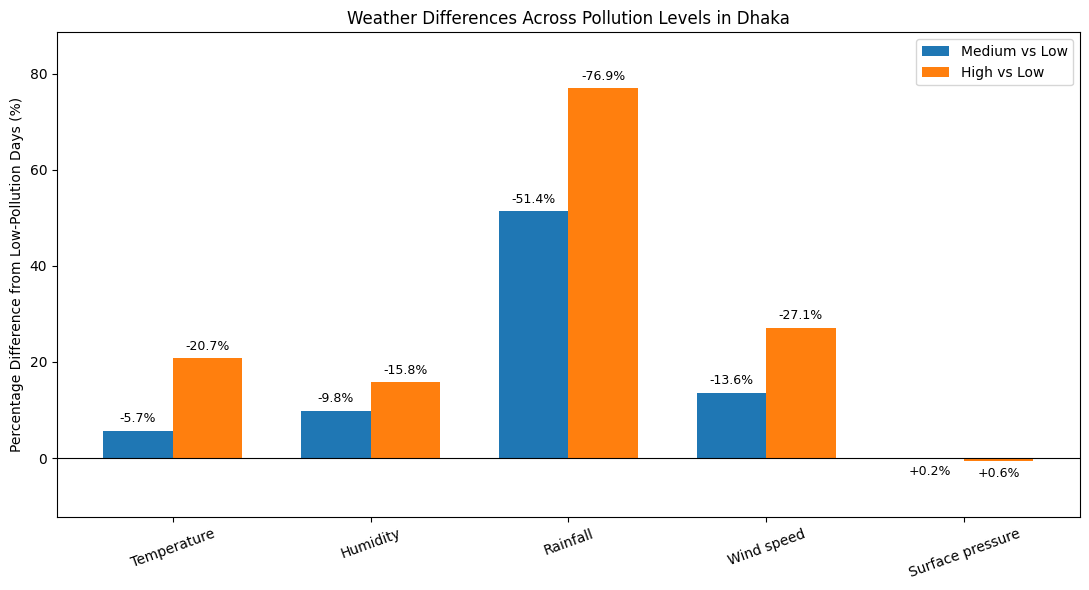

In [80]:

import matplotlib.pyplot as plt

labels = [
    "Temperature",
    "Humidity",
    "Rainfall",
    "Wind speed",
    "Surface pressure"
]

x = range(len(labels))
width = 0.35

plt.figure(figsize=(11, 6))


bars1 = plt.bar(
    [i - width/2 for i in x],
    -weather_pct.values,
    width,
    label="Medium vs Low"
)

bars2 = plt.bar(
    [i + width/2 for i in x],
    -high_pct.values,
    width,
    label="High vs Low"
)


for bars, values in [
    (bars1, weather_pct.values),
    (bars2, high_pct.values)
]:
    for bar, value in zip(bars, values):
        height = bar.get_height()

        plt.annotate(
            f"{value:+.1f}%",
            xy=(bar.get_x() + bar.get_width()/2, height),
            xytext=(0, 4 if height >= 0 else -4),
            textcoords="offset points",
            ha="center",
            va="bottom" if height >= 0 else "top",
            fontsize=9
        )

plt.axhline(0, color="black", linewidth=0.8)
plt.title("Weather Differences Across Pollution Levels in Dhaka")
plt.ylabel("Percentage Difference from Low-Pollution Days (%)")
plt.xticks(list(x), labels, rotation=20)
plt.legend()
plt.margins(y=0.15)
plt.tight_layout()
plt.show()


In [81]:
print(final_data["pollution_group"].value_counts(dropna=False))
print("\nExact labels:")
print(final_data["pollution_group"].unique())

pollution_group
Normal    971
High      324
Name: count, dtype: int64

Exact labels:
['Normal' 'High']


In [82]:
print(final_data.columns.tolist())

['date', 'pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide', 'ozone', 'aerosol_optical_depth', 'dust', 'uv_index', 'us_aqi', 'european_aqi', 'month', 'pollution_group', 'temperature_2m_mean', 'relative_humidity_2m_mean', 'precipitation_sum', 'wind_speed_10m_mean', 'surface_pressure_mean']


In [83]:
from scipy.stats import ttest_ind

normal = final_data.loc[
    final_data["pollution_group"] == "Normal",
    "wind_speed_10m_mean"
].dropna()

high = final_data.loc[
    final_data["pollution_group"] == "High",
    "wind_speed_10m_mean"
].dropna()

print("Normal days:", len(normal))
print("High days:", len(high))

print("Normal mean wind speed:", round(normal.mean(), 2))
print("High mean wind speed:", round(high.mean(), 2))

t_stat, p_value = ttest_ind(
    normal,
    high,
    equal_var=False
)

print("\nt-statistic:", round(t_stat, 3))
print("p-value:", p_value)

Normal days: 971
High days: 324
Normal mean wind speed: 7.64
High mean wind speed: 6.12

t-statistic: 14.25
p-value: 3.165636307244849e-41


In [84]:
import pandas as pd
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

weather_cols = [
    "temperature_2m_mean",
    "relative_humidity_2m_mean",
    "precipitation_sum",
    "surface_pressure_mean"
]

results = []

for col in weather_cols:
    normal = final_data.loc[
        final_data["pollution_group"] == "Normal", col
    ].dropna()

    high = final_data.loc[
        final_data["pollution_group"] == "High", col
    ].dropna()

    t_stat, p_value = ttest_ind(
        normal, high, equal_var=False
    )

    results.append({
        "Weather variable": col,
        "Normal mean": normal.mean(),
        "High mean": high.mean(),
        "Difference (High - Normal)": high.mean() - normal.mean(),
        "t-statistic": t_stat,
        "p-value": p_value
    })

results_df = pd.DataFrame(results)

# Adjust for testing multiple weather variables
results_df["Adjusted p-value"] = multipletests(
    results_df["p-value"],
    method="holm"
)[1]

print(results_df.round(4).to_string(index=False))

         Weather variable  Normal mean  High mean  Difference (High - Normal)  t-statistic  p-value  Adjusted p-value
      temperature_2m_mean      26.0855    21.4955                     -4.5900      20.7280      0.0               0.0
relative_humidity_2m_mean      75.2697    67.8104                     -7.4594      19.2164      0.0               0.0
        precipitation_sum       4.5357     1.5900                     -2.9457       6.8177      0.0               0.0
    surface_pressure_mean    1006.6546  1011.5699                      4.9153     -20.7958      0.0               0.0


In [85]:

import pandas as pd

combined_data["date"] = pd.to_datetime(combined_data["date"])
combined_data["month_num"] = combined_data["date"].dt.month

def assign_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Pre-monsoon"
    elif month in [6, 7, 8, 9]:
        return "Monsoon"
    else:
        return "Post-monsoon"

combined_data["season"] = combined_data["month_num"].apply(assign_season)

print(combined_data[["date", "month_num", "season"]].head())


        date  month_num   season
0 2022-08-04          8  Monsoon
1 2022-08-05          8  Monsoon
2 2022-08-06          8  Monsoon
3 2022-08-07          8  Monsoon
4 2022-08-08          8  Monsoon


In [86]:
import statsmodels.formula.api as smf

model_data = final_data[
    [
        "pm2_5",
        "temperature_2m_mean",
        "relative_humidity_2m_mean",
        "precipitation_sum",
        "wind_speed_10m_mean",
        "surface_pressure_mean",
        "season"
    ]
].dropna().copy()

model = smf.ols(
    "pm2_5 ~ temperature_2m_mean + relative_humidity_2m_mean + "
    "precipitation_sum + wind_speed_10m_mean + surface_pressure_mean "
    "+ C(season)",
    data=model_data
).fit()

print(model.summary())

KeyError: "['season'] not in index"

In [87]:
seasonal_pollution = (
    combined_data
    .groupby("season")["pm2_5"]
    .mean()
    .reindex(["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"])
)

print(seasonal_pollution.round(2))


season
Winter          84.95
Pre-monsoon     46.91
Monsoon         21.90
Post-monsoon    57.24
Name: pm2_5, dtype: float64


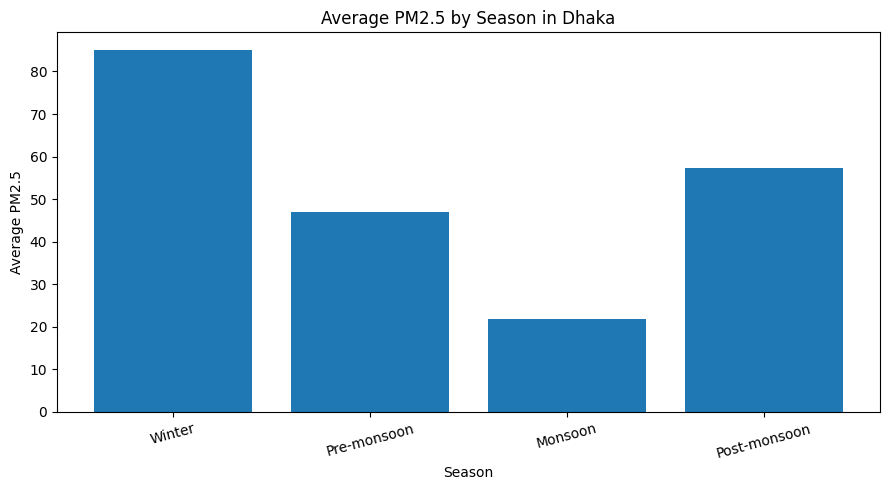

In [118]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    seasonal_pollution.index,
    seasonal_pollution.values
)

plt.title("Average PM2.5 by Season in Dhaka")
plt.xlabel("Season")
plt.ylabel("Average PM2.5")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [88]:
pollutants = [
    "pm2_5",
    "pm10",
    "carbon_monoxide",
    "nitrogen_dioxide",
    "sulphur_dioxide",
    "ozone"
]

seasonal_pollutants = (
    combined_data
    .groupby("season")[pollutants]
    .mean()
    .reindex(["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"])
)

display(seasonal_pollutants.round(2))

,pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone
season,,,,,,
Winter,84.95,105.44,880.06,44.56,18.09,69.43
Pre-monsoon,46.91,66.76,553.90,32.71,13.55,85.31
Monsoon,21.90,30.83,308.14,20.01,9.05,58.97
Post-monsoon,57.24,75.42,747.23,43.10,16.56,71.65


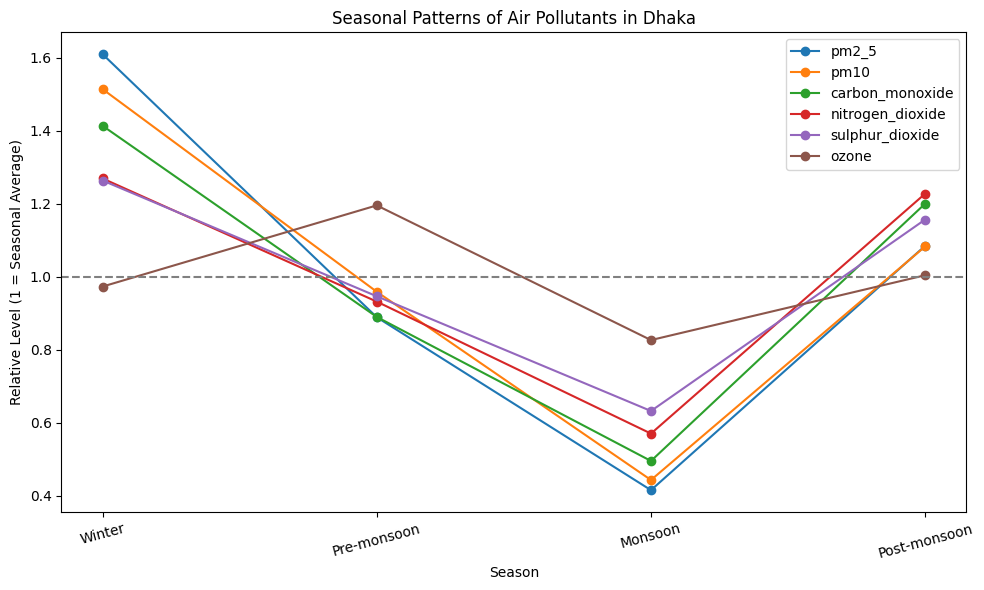

In [89]:

import matplotlib.pyplot as plt
seasonal_relative = seasonal_pollutants / seasonal_pollutants.mean()

plt.figure(figsize=(10, 6))

for pollutant in seasonal_relative.columns:
    plt.plot(
        seasonal_relative.index,
        seasonal_relative[pollutant],
        marker="o",
        label=pollutant
    )

plt.axhline(y=1, color="gray", linestyle="--")
plt.title("Seasonal Patterns of Air Pollutants in Dhaka")
plt.xlabel("Season")
plt.ylabel("Relative Level (1 = Seasonal Average)")
plt.legend()
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [90]:

pollutants = [
    "pm2_5",
    "pm10",
    "carbon_monoxide",
    "nitrogen_dioxide",
    "sulphur_dioxide",
    "ozone"
]

weather_columns = [
    "temperature_2m_mean",
    "relative_humidity_2m_mean",
    "precipitation_sum",
    "wind_speed_10m_mean",
    "surface_pressure_mean"
]

# Combine pollutants and weather variables
selected_columns = pollutants + weather_columns

# Calculate their correlations
weather_pollution_corr = combined_data[selected_columns].corr()

# Show only pollutant-to-weather correlations
display(
    weather_pollution_corr.loc[pollutants, weather_columns].round(2)
)


,temperature_2m_mean,relative_humidity_2m_mean,precipitation_sum,wind_speed_10m_mean,surface_pressure_mean
pm2_5,-0.55,-0.58,-0.20,-0.42,0.58
pm10,-0.47,-0.54,-0.18,-0.38,0.51
carbon_monoxide,-0.50,-0.58,-0.19,-0.42,0.52
nitrogen_dioxide,-0.37,-0.46,-0.15,-0.35,0.38
sulphur_dioxide,-0.40,-0.49,-0.17,-0.36,0.43
ozone,0.07,-0.19,-0.09,-0.00,0.01


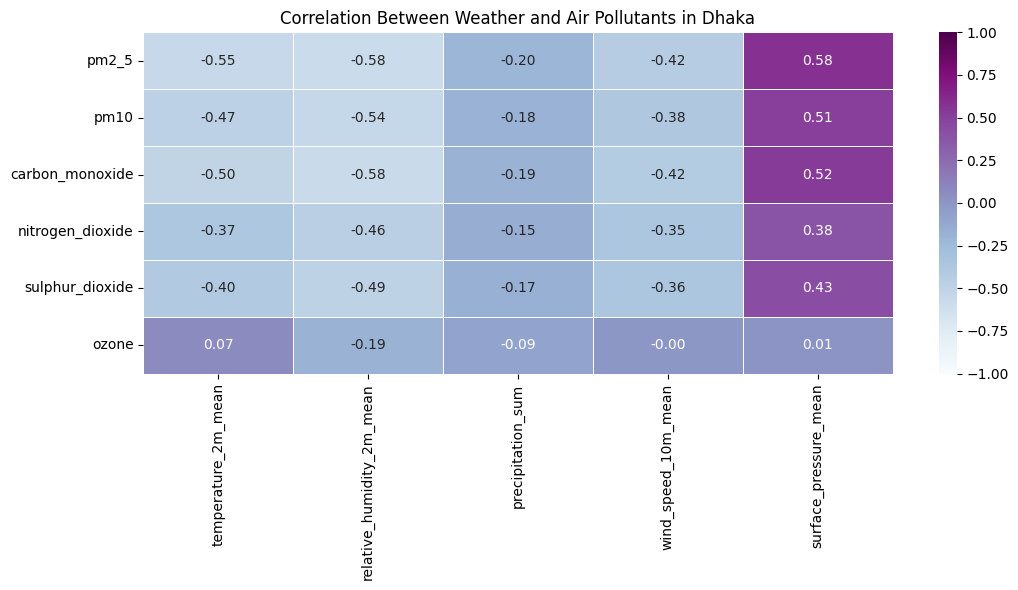

In [91]:

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

sns.heatmap(
    weather_pollution_corr.loc[pollutants, weather_columns],
    annot=True,
    cmap="BuPu",
    center=0,
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Weather and Air Pollutants in Dhaka")
plt.tight_layout()
plt.show()


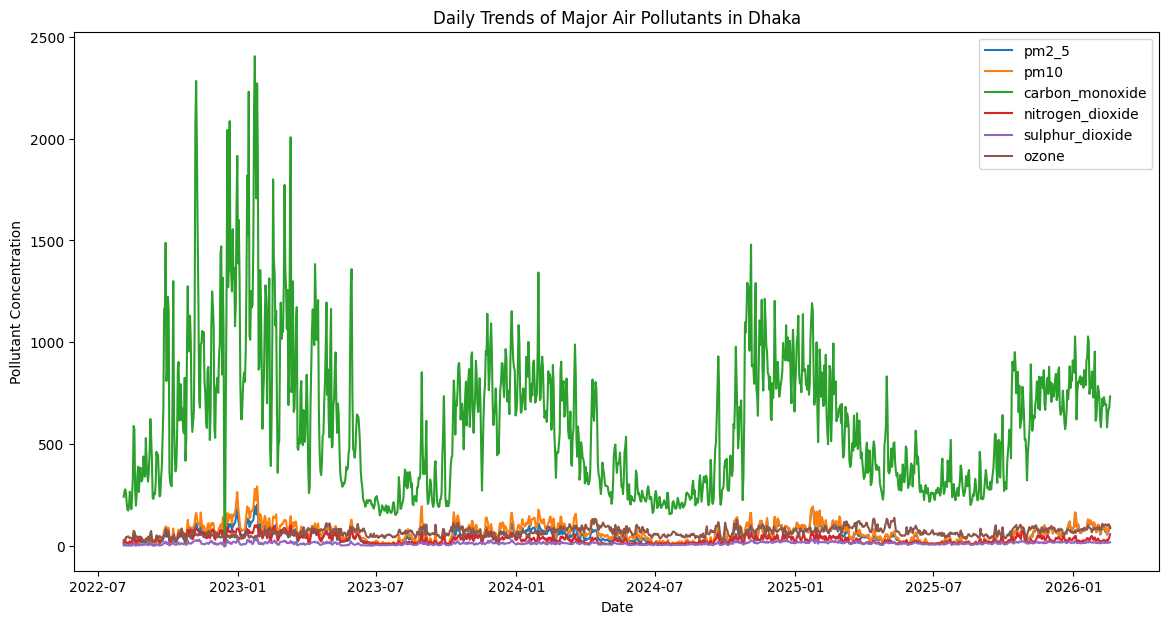

In [92]:
pollutants = [
    "pm2_5",
    "pm10",
    "carbon_monoxide",
    "nitrogen_dioxide",
    "sulphur_dioxide",
    "ozone"
]

plt.figure(figsize=(14, 7))

for pollutant in pollutants:
    plt.plot(
        combined_data["date"],
        combined_data[pollutant],
        label=pollutant
    )

plt.title("Daily Trends of Major Air Pollutants in Dhaka")
plt.xlabel("Date")
plt.ylabel("Pollutant Concentration")
plt.legend()

plt.show()

In [93]:
from sklearn.preprocessing import StandardScaler

pollutants = [
    "pm2_5",
    "pm10",
    "carbon_monoxide",
    "nitrogen_dioxide",
    "sulphur_dioxide",
    "ozone"
]

scaler = StandardScaler()

standardized_pollutants = pd.DataFrame(
    scaler.fit_transform(combined_data[pollutants]),
    columns=pollutants
)

standardized_pollutants.head()

,pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone
0,-1.174636,-1.158459,-1.016396,-0.722986,-1.589752,-1.971675
1,-1.134102,-1.109854,-0.943046,-0.679299,-1.422746,-1.800113
2,-1.118792,-1.100662,-0.910216,-0.351538,-1.456276,-2.069518
3,-1.177914,-1.165104,-0.969452,-0.617698,-1.477555,-1.219084
4,-1.252842,-1.244736,-1.107429,-0.822469,-1.652943,-1.223105


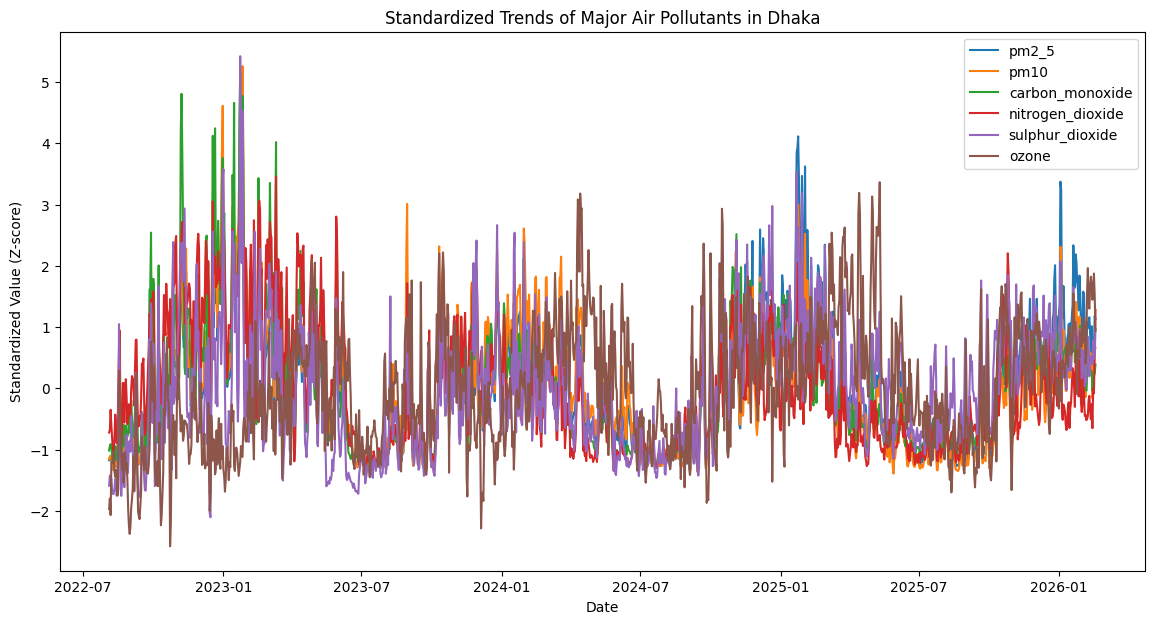

In [94]:
plt.figure(figsize=(14, 7))

for pollutant in pollutants:
    plt.plot(
        combined_data["date"],
        standardized_pollutants[pollutant],
        label=pollutant
    )

plt.title("Standardized Trends of Major Air Pollutants in Dhaka")
plt.xlabel("Date")
plt.ylabel("Standardized Value (Z-score)")
plt.legend()

plt.show()

In [95]:
high_pm25 = combined_data[
    combined_data["pm2_5"] > combined_data["pm2_5"].quantile(0.90)
].copy()

high_pm25[[
    "date",
    "pm2_5",
    "temperature_2m_mean",
    "relative_humidity_2m_mean",
    "precipitation_sum",
    "wind_speed_10m_mean"
]].head(10)

,date,pm2_5,temperature_2m_mean,relative_humidity_2m_mean,precipitation_sum,wind_speed_10m_mean
94,2022-11-06,102.062500,20.391583,65.738721,0.0,6.594966
95,2022-11-07,114.166667,20.007670,59.611495,0.0,6.001943
96,2022-11-08,100.954167,19.648119,61.113544,0.0,6.497727
101,2022-11-13,114.579167,19.758071,69.742817,0.0,4.958087
130,2022-12-12,100.033333,20.710389,68.262949,0.0,7.442941
135,2022-12-17,100.850000,21.220276,64.005235,0.0,3.971194
136,2022-12-18,112.916667,18.153704,71.429382,0.0,4.825801
138,2022-12-20,98.620833,21.960714,67.939511,0.0,5.633267
139,2022-12-21,109.025000,17.588775,67.651525,0.0,6.877151
140,2022-12-22,97.704167,20.276951,69.693895,0.0,5.219208


In [96]:
high_pm25[
    [
        "pm2_5",
        "temperature_2m_mean",
        "relative_humidity_2m_mean",
        "precipitation_sum",
        "wind_speed_10m_mean",
        "surface_pressure_mean"
    ]
].mean()

,0
pm2_5,117.314167
temperature_2m_mean,20.536498
relative_humidity_2m_mean,67.248650
precipitation_sum,1.612372
wind_speed_10m_mean,5.967071
surface_pressure_mean,1012.680027


In [97]:
combined_data[
    [
        "pm2_5",
        "temperature_2m_mean",
        "relative_humidity_2m_mean",
        "precipitation_sum",
        "wind_speed_10m_mean",
        "surface_pressure_mean"
    ]
].mean()

,0
pm2_5,50.978196
temperature_2m_mean,24.937099
relative_humidity_2m_mean,73.403461
precipitation_sum,3.798700
wind_speed_10m_mean,7.262051
surface_pressure_mean,1007.884336


In [98]:
comparison = pd.DataFrame({
    "All Days": combined_data[
        [
            "temperature_2m_mean",
            "relative_humidity_2m_mean",
            "precipitation_sum",
            "wind_speed_10m_mean",
            "surface_pressure_mean"
        ]
    ].mean(),

    "High PM2.5 Days": high_pm25[
        [
            "temperature_2m_mean",
            "relative_humidity_2m_mean",
            "precipitation_sum",
            "wind_speed_10m_mean",
            "surface_pressure_mean"
        ]
    ].mean()
})

comparison["Difference"] = (
    comparison["High PM2.5 Days"] - comparison["All Days"]
)

comparison

,All Days,High PM2.5 Days,Difference
temperature_2m_mean,24.937099,20.536498,-4.400601
relative_humidity_2m_mean,73.403461,67.248650,-6.154811
precipitation_sum,3.798700,1.612372,-2.186328
wind_speed_10m_mean,7.262051,5.967071,-1.294980
surface_pressure_mean,1007.884336,1012.680027,4.795691


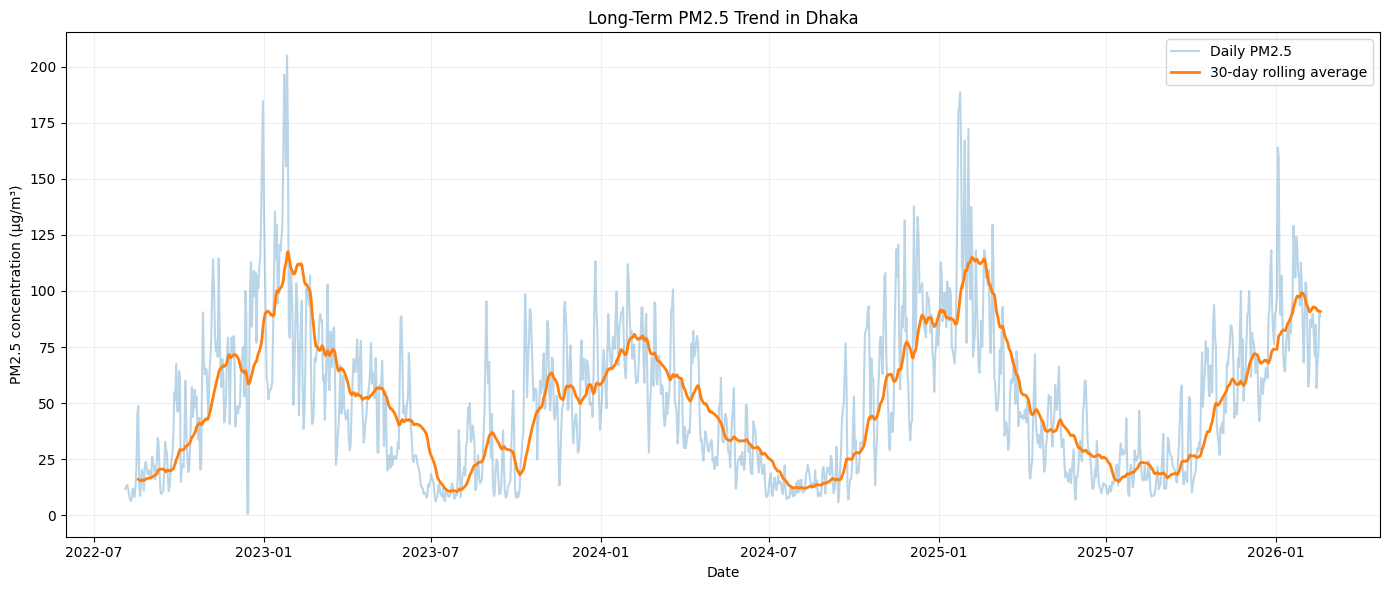

In [99]:
import matplotlib.pyplot as plt

trend_data = combined_data.sort_values("date").copy()

trend_data["pm25_30day_avg"] = (
    trend_data["pm2_5"].rolling(window=30, min_periods=15).mean()
)

# Plot daily PM2.5 and its rolling average
plt.figure(figsize=(14, 6))

plt.plot(
    trend_data["date"],
    trend_data["pm2_5"],
    alpha=0.3,
    label="Daily PM2.5"
)

plt.plot(
    trend_data["date"],
    trend_data["pm25_30day_avg"],
    linewidth=2,
    label="30-day rolling average"
)

plt.title("Long-Term PM2.5 Trend in Dhaka")
plt.xlabel("Date")
plt.ylabel("PM2.5 concentration (µg/m³)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Average PM2.5 by year:


,pm2_5
year,
2022,48.86
2023,50.31
2024,47.64
2025,50.39
2026,91.68


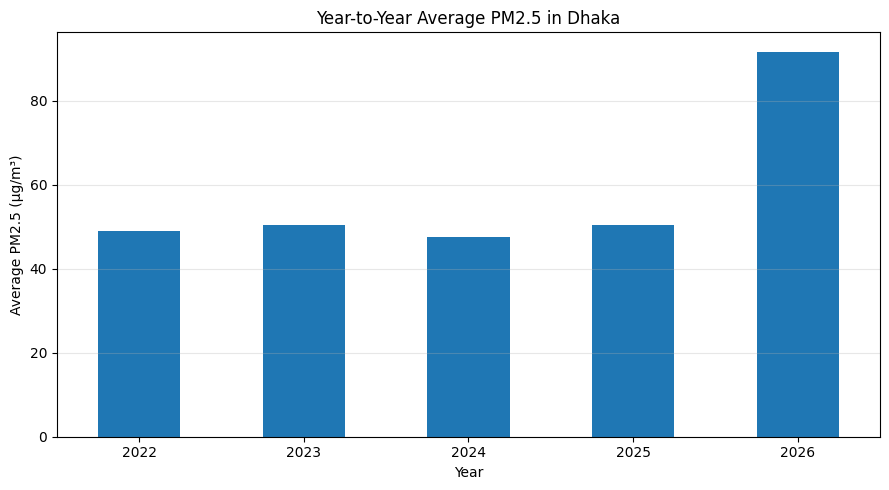

In [101]:
import matplotlib.pyplot as plt

combined_data["year"] = combined_data["date"].dt.year
yearly_pm25 = combined_data.groupby("year")["pm2_5"].mean()
print("Average PM2.5 by year:")
display(yearly_pm25.round(2))

plt.figure(figsize=(9, 5))

yearly_pm25.plot(kind="bar")

plt.title("Year-to-Year Average PM2.5 in Dhaka")
plt.xlabel("Year")
plt.ylabel("Average PM2.5 (µg/m³)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [102]:
final_data = combined_data.copy()

In [103]:
import sqlite3

conn = sqlite3.connect("dhaka_air_quality.db")

final_data.to_sql(
    "air_quality",
    conn,
    if_exists="replace",
    index=False
)

print("Data loaded successfully!")

Data loaded successfully!


In [135]:
print("Final dataset shape:", final_data.shape)

Final dataset shape: (1298, 23)


In [137]:
final_data.columns.tolist()

['date',
 'pm10',
 'pm2_5',
 'carbon_monoxide',
 'nitrogen_dioxide',
 'sulphur_dioxide',
 'ozone',
 'aerosol_optical_depth',
 'dust',
 'uv_index',
 'us_aqi',
 'european_aqi',
 'month',
 'pollution_group',
 'temperature_2m_mean',
 'relative_humidity_2m_mean',
 'precipitation_sum',
 'wind_speed_10m_mean',
 'surface_pressure_mean',
 'pollution_level',
 'month_num',
 'season',
 'year']

In [138]:
pd.read_sql("SELECT * FROM air_quality LIMIT 5", conn)

,date,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,...,pollution_group,temperature_2m_mean,relative_humidity_2m_mean,precipitation_sum,wind_speed_10m_mean,surface_pressure_mean,pollution_level,month_num,season,year
0,2022-08-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Normal,27.745071,83.069569,0.000000,10.264790,1005.002220,None,8,Monsoon,2022
1,2022-08-02 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Normal,26.792604,83.286791,4.490907,11.439560,1001.911132,None,8,Monsoon,2022
2,2022-08-03 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Normal,27.971533,79.327638,0.000000,7.828717,1005.985768,None,8,Monsoon,2022
3,2022-08-04 00:00:00,17.227778,11.655556,242.222222,19.538889,3.600000,28.944444,0.165000,0.0,2.761111,...,Normal,29.284545,85.968169,12.435041,9.458539,1006.667206,Low,8,Monsoon,2022
4,2022-08-05 00:00:00,19.320833,13.012500,267.916667,20.395833,4.679167,32.500000,0.158333,0.0,2.320833,...,Normal,26.648770,81.300161,16.408011,7.559944,1003.797747,Low,8,Monsoon,2022


In [139]:
import zipfile

with zipfile.ZipFile("your_file.zip", "r") as zip_ref:
    zip_ref.extractall("merged_data")

FileNotFoundError: [Errno 2] No such file or directory: 'your_file.zip'

In [105]:
!pip install duckdb

In [106]:
import duckdb

con = duckdb.connect()
con.register("air_quality", combined_data)
print("Registered 'air_quality' view in DuckDB successfully.")

Registered 'air_quality' view in DuckDB successfully.


In [107]:
con.register("air_quality", combined_data)
print("Table registration refreshed.")

Table registration refreshed.


1.Which days had the largest PM2.5 increases?


In [109]:
query = """
SELECT
    date,
    pm2_5,
    LAG(pm2_5) OVER (ORDER BY date) AS previous_day_pm25,
    ROUND(
        pm2_5 - LAG(pm2_5) OVER (ORDER BY date),
        2
    ) AS daily_increase
FROM air_quality
WHERE pm2_5 IS NOT NULL
ORDER BY daily_increase DESC
LIMIT 10;
"""

result = con.execute(query).df()
display(result)

,date,pm2_5,previous_day_pm25,daily_increase
0,2026-01-03,163.904167,97.483333,66.42
1,2022-12-16,59.662500,0.650000,59.01
2,2025-02-01,127.370833,76.937500,50.43
3,2023-01-26,205.100000,155.625000,49.47
4,2024-12-04,91.562500,42.112500,49.45
5,2022-12-12,100.033333,52.962500,47.07
6,2024-12-05,137.737500,91.562500,46.17
7,2025-02-02,172.225000,127.370833,44.85
8,2025-02-28,129.454167,84.675000,44.78
9,2022-11-13,114.579167,70.666667,43.91


2.What changed alongside those major increases?

In [110]:
query = """
WITH daily_changes AS (
    SELECT
        date,
        pm2_5,
        pm10,
        carbon_monoxide,
        nitrogen_dioxide,
        sulphur_dioxide,
        ozone,
        temperature_2m_mean,
        relative_humidity_2m_mean,
        precipitation_sum,
        wind_speed_10m_mean,
        surface_pressure_mean,

        LAG(pm2_5) OVER (ORDER BY date) AS previous_pm25,
        LAG(pm10) OVER (ORDER BY date) AS previous_pm10,
        LAG(carbon_monoxide) OVER (ORDER BY date) AS previous_co,
        LAG(nitrogen_dioxide) OVER (ORDER BY date) AS previous_no2,
        LAG(sulphur_dioxide) OVER (ORDER BY date) AS previous_so2,
        LAG(ozone) OVER (ORDER BY date) AS previous_ozone,

        LAG(temperature_2m_mean) OVER (ORDER BY date) AS previous_temp,
        LAG(relative_humidity_2m_mean) OVER (ORDER BY date) AS previous_humidity,
        LAG(precipitation_sum) OVER (ORDER BY date) AS previous_rain,
        LAG(wind_speed_10m_mean) OVER (ORDER BY date) AS previous_wind,
        LAG(surface_pressure_mean) OVER (ORDER BY date) AS previous_pressure

    FROM air_quality
)

SELECT
    date,
    ROUND(pm2_5 - previous_pm25, 2) AS pm25_change,
    ROUND(pm10 - previous_pm10, 2) AS pm10_change,
    ROUND(carbon_monoxide - previous_co, 2) AS co_change,
    ROUND(nitrogen_dioxide - previous_no2, 2) AS no2_change,
    ROUND(sulphur_dioxide - previous_so2, 2) AS so2_change,
    ROUND(ozone - previous_ozone, 2) AS ozone_change,
    ROUND(temperature_2m_mean - previous_temp, 2) AS temperature_change,
    ROUND(relative_humidity_2m_mean - previous_humidity, 2) AS humidity_change,
    ROUND(precipitation_sum - previous_rain, 2) AS rainfall_change,
    ROUND(wind_speed_10m_mean - previous_wind, 2) AS wind_change,
    ROUND(surface_pressure_mean - previous_pressure, 2) AS pressure_change

FROM daily_changes
WHERE pm2_5 IS NOT NULL
  AND previous_pm25 IS NOT NULL
ORDER BY pm25_change DESC
LIMIT 10;
"""

result = con.execute(query).df()
display(result)

,date,pm25_change,pm10_change,co_change,no2_change,so2_change,ozone_change,temperature_change,humidity_change,rainfall_change,wind_change,pressure_change
0,2026-01-03,66.42,67.35,177.79,10.47,9.31,7.83,0.75,4.27,0.00,0.67,2.15
1,2022-12-16,59.01,84.61,673.88,41.98,11.60,27.17,0.69,1.80,0.00,0.01,5.35
2,2025-02-01,50.43,50.60,230.71,23.65,10.89,-4.46,0.56,1.66,4.68,0.97,-0.89
3,2023-01-26,49.47,70.69,564.25,10.94,16.10,-0.38,-2.58,-3.08,0.00,-0.79,0.46
4,2024-12-04,49.45,51.58,94.71,3.68,4.38,20.12,-0.39,-5.96,0.00,-1.08,-3.71
5,2022-12-12,47.07,67.24,474.87,10.43,11.22,21.00,2.30,2.03,0.00,1.47,-4.96
6,2024-12-05,46.17,49.62,381.92,15.71,3.43,-16.04,1.96,2.58,1.61,-0.20,3.03
7,2025-02-02,44.85,47.15,223.83,15.68,-0.43,-7.38,0.49,-0.07,-1.10,-2.18,-0.65
8,2025-02-28,44.78,49.76,3.38,18.01,11.48,-5.96,-0.33,-2.32,2.14,0.10,0.74
9,2022-11-13,43.91,64.17,309.88,9.74,0.07,-0.92,0.96,2.60,0.00,0.26,0.84


3.Detect sustained pollution episodes

In [111]:

query = """
WITH threshold AS (
    SELECT QUANTILE_CONT(pm2_5, 0.90) AS pm25_limit
    FROM air_quality
    WHERE pm2_5 IS NOT NULL
),
daily AS (
    SELECT
        CAST(date AS DATE) AS date,
        AVG(pm2_5) AS pm2_5
    FROM air_quality
    WHERE pm2_5 IS NOT NULL
    GROUP BY CAST(date AS DATE)
),
classified AS (
    SELECT
        d.date,
        d.pm2_5,
        CASE
            WHEN d.pm2_5 > t.pm25_limit THEN 1
            ELSE 0
        END AS is_high
    FROM daily d
    CROSS JOIN threshold t
),
marked AS (
    SELECT
        *,
        LAG(date) OVER (ORDER BY date) AS previous_date,
        LAG(is_high) OVER (ORDER BY date) AS previous_high
    FROM classified
),
episode_starts AS (
    SELECT
        *,
        CASE
            WHEN is_high = 1
             AND (
                 previous_high = 0
                 OR previous_high IS NULL
                 OR date != previous_date + INTERVAL '1 day'
             )
            THEN 1
            ELSE 0
        END AS new_episode
    FROM marked
),
numbered AS (
    SELECT
        *,
        SUM(new_episode) OVER (
            ORDER BY date
            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
        ) AS episode_id
    FROM episode_starts
),
episodes AS (
    SELECT
        episode_id,
        MIN(date) AS start_date,
        MAX(date) AS end_date,
        COUNT(*) AS duration_days,
        ROUND(MAX(pm2_5), 2) AS peak_pm25,
        ROUND(AVG(pm2_5), 2) AS average_pm25
    FROM numbered
    WHERE is_high = 1
    GROUP BY episode_id
)
SELECT *
FROM episodes
WHERE duration_days >= 3
ORDER BY peak_pm25 DESC;
"""

episodes = con.execute(query).df()
display(episodes)

,episode_id,start_date,end_date,duration_days,peak_pm25,average_pm25
0,8.0,2023-01-17,2023-01-27,11,205.10,150.04
1,33.0,2025-01-20,2025-01-30,11,188.65,144.26
2,6.0,2022-12-25,2023-01-02,9,184.63,129.06
3,34.0,2025-02-01,2025-02-06,6,172.23,126.83
4,41.0,2026-01-02,2026-01-05,4,163.90,129.89
5,7.0,2023-01-12,2023-01-15,4,135.45,121.99
6,27.0,2024-12-08,2024-12-14,7,132.97,111.29
7,43.0,2026-01-19,2026-01-26,8,129.11,113.33
8,24.0,2024-11-15,2024-11-18,4,120.66,111.82
9,36.0,2025-02-18,2025-02-24,7,118.23,108.10


4.Start and end date

In [112]:

query = """
WITH threshold AS (
    SELECT QUANTILE_CONT(pm2_5, 0.90) AS pm25_limit
    FROM air_quality
    WHERE pm2_5 IS NOT NULL
),
daily AS (
    SELECT
        CAST(date AS DATE) AS date,
        AVG(pm2_5) AS pm2_5
    FROM air_quality
    WHERE pm2_5 IS NOT NULL
    GROUP BY CAST(date AS DATE)
),
classified AS (
    SELECT
        d.date,
        d.pm2_5,
        CASE
            WHEN d.pm2_5 > t.pm25_limit THEN 1
            ELSE 0
        END AS is_high
    FROM daily d
    CROSS JOIN threshold t
),
marked AS (
    SELECT
        *,
        LAG(date) OVER (ORDER BY date) AS previous_date,
        LAG(is_high) OVER (ORDER BY date) AS previous_high
    FROM classified
),
episode_starts AS (
    SELECT
        *,
        CASE
            WHEN is_high = 1
             AND (
                 previous_high = 0
                 OR previous_high IS NULL
                 OR date != previous_date + INTERVAL '1 day'
             )
            THEN 1
            ELSE 0
        END AS new_episode
    FROM marked
),
numbered AS (
    SELECT
        *,
        SUM(new_episode) OVER (
            ORDER BY date
            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
        ) AS episode_id
    FROM episode_starts
),
episodes AS (
    SELECT
        episode_id,
        MIN(date) AS start_date,
        MAX(date) AS end_date,
        COUNT(*) AS duration_days,
        ROUND(MAX(pm2_5), 2) AS peak_pm25,
        ROUND(AVG(pm2_5), 2) AS average_pm25
    FROM numbered
    WHERE is_high = 1
    GROUP BY episode_id
)
SELECT *
FROM episodes
WHERE duration_days >= 3
ORDER BY peak_pm25 DESC;
"""

episodes = con.execute(query).df()
display(episodes)


,episode_id,start_date,end_date,duration_days,peak_pm25,average_pm25
0,8.0,2023-01-17,2023-01-27,11,205.10,150.04
1,33.0,2025-01-20,2025-01-30,11,188.65,144.26
2,6.0,2022-12-25,2023-01-02,9,184.63,129.06
3,34.0,2025-02-01,2025-02-06,6,172.23,126.83
4,41.0,2026-01-02,2026-01-05,4,163.90,129.89
5,7.0,2023-01-12,2023-01-15,4,135.45,121.99
6,27.0,2024-12-08,2024-12-14,7,132.97,111.29
7,43.0,2026-01-19,2026-01-26,8,129.11,113.33
8,24.0,2024-11-15,2024-11-18,4,120.66,111.82
9,36.0,2025-02-18,2025-02-24,7,118.23,108.10


5.Calculate the growth rate of each episode

In [113]:

query = """
WITH threshold AS (
    SELECT QUANTILE_CONT(pm2_5, 0.90) AS pm25_limit
    FROM air_quality
    WHERE pm2_5 IS NOT NULL
),
daily AS (
    SELECT
        CAST(date AS DATE) AS date,
        AVG(pm2_5) AS pm2_5
    FROM air_quality
    WHERE pm2_5 IS NOT NULL
    GROUP BY CAST(date AS DATE)
),
classified AS (
    SELECT
        d.date,
        d.pm2_5,
        CASE WHEN d.pm2_5 > t.pm25_limit THEN 1 ELSE 0 END AS is_high
    FROM daily d
    CROSS JOIN threshold t
),
previous_values AS (
    SELECT
        *,
        LAG(date) OVER (ORDER BY date) AS previous_date,
        LAG(is_high) OVER (ORDER BY date) AS previous_high
    FROM classified
),
episode_flags AS (
    SELECT
        *,
        CASE
            WHEN is_high = 1
             AND (
                 previous_high = 0
                 OR previous_high IS NULL
                 OR date != previous_date + INTERVAL '1 day'
             )
            THEN 1 ELSE 0
        END AS episode_start
    FROM previous_values
),
episode_groups AS (
    SELECT
        *,
        SUM(episode_start) OVER (
            ORDER BY date
            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
        ) AS episode_id
    FROM episode_flags
),
episodes AS (
    SELECT
        episode_id,
        MIN(date) AS start_date,
        MAX(date) AS end_date,
        COUNT(*) AS duration_days,
        FIRST(pm2_5 ORDER BY date) AS starting_pm25,
        LAST(pm2_5 ORDER BY date) AS ending_pm25,
        MAX(pm2_5) AS peak_pm25,
        AVG(pm2_5) AS average_pm25
    FROM episode_groups
    WHERE is_high = 1
    GROUP BY episode_id
    HAVING COUNT(*) >= 3
)
SELECT
    episode_id,
    ROUND(starting_pm25, 2) AS starting_pm25,
    ROUND(ending_pm25, 2) AS ending_pm25,
    ROUND(ending_pm25 - starting_pm25, 2) AS net_change,
    ROUND(
        100.0 * (ending_pm25 - starting_pm25)
        / NULLIF(starting_pm25, 0),
        2
    ) AS growth_percent,
    ROUND(peak_pm25, 2) AS peak_pm25,
    ROUND(average_pm25, 2) AS average_pm25
FROM episodes
ORDER BY start_date;
"""

episode_growth = con.execute(query).df()
display(episode_growth)


,episode_id,starting_pm25,ending_pm25,net_change,growth_percent,peak_pm25,average_pm25
0,1.0,102.06,100.95,-1.11,-1.09,114.17,105.73
1,5.0,98.62,108.15,9.52,9.66,109.03,103.37
2,6.0,106.65,111.18,4.54,4.25,184.63,129.06
3,7.0,108.59,129.52,20.93,19.27,135.45,121.99
4,8.0,100.82,169.58,68.76,68.20,205.10,150.04
5,12.0,100.96,99.51,-1.45,-1.44,100.96,98.90
6,24.0,101.64,120.66,19.02,18.71,120.66,111.82
7,27.0,115.23,103.53,-11.70,-10.15,132.97,111.29
8,28.0,99.29,96.92,-2.37,-2.39,99.29,97.70
9,33.0,100.48,118.67,18.19,18.10,188.65,144.26


6.Which pollutants are most consistently elevated during PM2.5 episodes?

In [114]:

query = """
WITH threshold AS (
    SELECT
        QUANTILE_CONT(pm2_5, 0.90) AS pm25_limit
    FROM air_quality
    WHERE pm2_5 IS NOT NULL
),

daily AS (
    SELECT
        CAST(date AS DATE) AS date,
        AVG(pm2_5) AS pm2_5,
        AVG(pm10) AS pm10,
        AVG(carbon_monoxide) AS co,
        AVG(nitrogen_dioxide) AS no2,
        AVG(sulphur_dioxide) AS so2,
        AVG(ozone) AS ozone
    FROM air_quality
    GROUP BY CAST(date AS DATE)
),

classified AS (
    SELECT
        d.*,
        CASE
            WHEN d.pm2_5 > t.pm25_limit THEN 1
            ELSE 0
        END AS is_high
    FROM daily d
    CROSS JOIN threshold t
),

with_previous AS (
    SELECT
        *,
        LAG(date) OVER (ORDER BY date) AS previous_date,
        LAG(is_high) OVER (ORDER BY date) AS previous_high
    FROM classified
),

episode_flags AS (
    SELECT
        *,
        CASE
            WHEN is_high = 1 AND (
                previous_high = 0
                OR previous_high IS NULL
                OR date != previous_date + INTERVAL '1 day'
            )
            THEN 1
            ELSE 0
        END AS episode_start
    FROM with_previous
),

numbered AS (
    SELECT
        *,
        SUM(episode_start) OVER (
            ORDER BY date
            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
        ) AS episode_id
    FROM episode_flags
),

episode_days AS (
    SELECT *
    FROM numbered
    WHERE is_high = 1
),

valid_episodes AS (
    SELECT episode_id
    FROM episode_days
    GROUP BY episode_id
    HAVING COUNT(*) >= 3
),

valid_episode_days AS (
    SELECT e.*
    FROM episode_days e
    JOIN valid_episodes v
        ON e.episode_id = v.episode_id
),

normal_days AS (
    SELECT *
    FROM classified
    WHERE is_high = 0
),

normal_thresholds AS (
    SELECT
        QUANTILE_CONT(pm10, 0.75) AS pm10_p75,
        QUANTILE_CONT(co, 0.75) AS co_p75,
        QUANTILE_CONT(no2, 0.75) AS no2_p75,
        QUANTILE_CONT(so2, 0.75) AS so2_p75,
        QUANTILE_CONT(ozone, 0.75) AS ozone_p75
    FROM normal_days
),

episode_summary AS (
    SELECT
        AVG(pm10) AS avg_pm10,
        AVG(co) AS avg_co,
        AVG(no2) AS avg_no2,
        AVG(so2) AS avg_so2,
        AVG(ozone) AS avg_ozone,

        COUNT(pm10) AS days_pm10,
        COUNT(co) AS days_co,
        COUNT(no2) AS days_no2,
        COUNT(so2) AS days_so2,
        COUNT(ozone) AS days_ozone,

        COUNT(*) FILTER (
            WHERE pm10 > t.pm10_p75
        ) AS high_pm10_days,

        COUNT(*) FILTER (
            WHERE co > t.co_p75
        ) AS high_co_days,

        COUNT(*) FILTER (
            WHERE no2 > t.no2_p75
        ) AS high_no2_days,

        COUNT(*) FILTER (
            WHERE so2 > t.so2_p75
        ) AS high_so2_days,

        COUNT(*) FILTER (
            WHERE ozone > t.ozone_p75
        ) AS high_ozone_days

    FROM valid_episode_days e
    CROSS JOIN normal_thresholds t
),

normal_summary AS (
    SELECT
        AVG(pm10) AS avg_pm10,
        AVG(co) AS avg_co,
        AVG(no2) AS avg_no2,
        AVG(so2) AS avg_so2,
        AVG(ozone) AS avg_ozone
    FROM normal_days
)

SELECT
    'PM10' AS pollutant,
    ROUND(e.avg_pm10, 2) AS episode_average,
    ROUND(n.avg_pm10, 2) AS normal_average,
    ROUND(t.pm10_p75, 2) AS normal_75th_percentile,
    ROUND(
        100.0 * e.high_pm10_days / NULLIF(e.days_pm10, 0), 2
    ) AS episode_days_elevated,
    ROUND(
        100.0 * (e.avg_pm10 - n.avg_pm10)
        / NULLIF(n.avg_pm10, 0), 2
    ) AS average_increase_pct
FROM episode_summary e
CROSS JOIN normal_summary n
CROSS JOIN normal_thresholds t

UNION ALL

SELECT
    'CO',
    ROUND(e.avg_co, 2),
    ROUND(n.avg_co, 2),
    ROUND(t.co_p75, 2),
    ROUND(100.0 * e.high_co_days / NULLIF(e.days_co, 0), 2),
    ROUND(
        100.0 * (e.avg_co - n.avg_co)
        / NULLIF(n.avg_co, 0), 2
    )
FROM episode_summary e
CROSS JOIN normal_summary n
CROSS JOIN normal_thresholds t

UNION ALL

SELECT
    'NO2',
    ROUND(e.avg_no2, 2),
    ROUND(n.avg_no2, 2),
    ROUND(t.no2_p75, 2),
    ROUND(100.0 * e.high_no2_days / NULLIF(e.days_no2, 0), 2),
    ROUND(
        100.0 * (e.avg_no2 - n.avg_no2)
        / NULLIF(n.avg_no2, 0), 2
    )
FROM episode_summary e
CROSS JOIN normal_summary n
CROSS JOIN normal_thresholds t

UNION ALL

SELECT
    'SO2',
    ROUND(e.avg_so2, 2),
    ROUND(n.avg_so2, 2),
    ROUND(t.so2_p75, 2),
    ROUND(100.0 * e.high_so2_days / NULLIF(e.days_so2, 0), 2),
    ROUND(
        100.0 * (e.avg_so2 - n.avg_so2)
        / NULLIF(n.avg_so2, 0), 2
    )
FROM episode_summary e
CROSS JOIN normal_summary n
CROSS JOIN normal_thresholds t

UNION ALL

SELECT
    'Ozone',
    ROUND(e.avg_ozone, 2),
    ROUND(n.avg_ozone, 2),
    ROUND(t.ozone_p75, 2),
    ROUND(100.0 * e.high_ozone_days / NULLIF(e.days_ozone, 0), 2),
    ROUND(
        100.0 * (e.avg_ozone - n.avg_ozone)
        / NULLIF(n.avg_ozone, 0), 2
    )
FROM episode_summary e
CROSS JOIN normal_summary n
CROSS JOIN normal_thresholds t

ORDER BY episode_days_elevated DESC;
"""

result = con.execute(query).df()
result


,pollutant,episode_average,normal_average,normal_75th_percentile,episode_days_elevated,average_increase_pct
0,PM10,148.49,58.57,84.37,100.00,153.54
1,CO,1180.57,539.26,742.79,89.29,118.93
2,SO2,23.78,12.83,17.04,88.10,85.27
3,NO2,58.59,31.16,41.98,71.43,88.06
4,Ozone,69.12,69.55,83.83,27.38,-0.62


7.weather conditions distinguish pollution episodes

In [115]:
con.execute("""
WITH threshold AS (
    SELECT
        QUANTILE_CONT(pm2_5, 0.90) AS threshold
    FROM air_quality
    WHERE pm2_5 IS NOT NULL
),

classified AS (
    SELECT
        *,
        CASE
            WHEN pm2_5 >= (SELECT threshold FROM threshold)
            THEN 'Episode'
            ELSE 'Non-episode'
        END AS period
    FROM air_quality
)

SELECT
    period,
    COUNT(*) AS observations,
    ROUND(AVG(temperature_2m_mean), 2) AS avg_temperature,
    ROUND(AVG(relative_humidity_2m_mean), 2) AS avg_humidity,
    ROUND(AVG(precipitation_sum), 2) AS avg_precipitation,
    ROUND(AVG(wind_speed_10m_mean), 2) AS avg_wind_speed,
    ROUND(AVG(surface_pressure_mean), 2) AS avg_pressure
FROM classified
GROUP BY period
ORDER BY period;
""").fetchdf()

,period,observations,avg_temperature,avg_humidity,avg_precipitation,avg_wind_speed,avg_pressure
0,Episode,130,20.54,67.25,1.61,5.97,1012.68
1,Non-episode,1165,25.43,74.09,4.04,7.41,1007.35


**Regression**

In [116]:
con.execute("""
SELECT
    date,
    pm2_5,
    pm10,
    us_aqi,
    european_aqi
FROM air_quality
ORDER BY pm2_5 DESC
LIMIT 10;
""").fetchdf()

,date,pm2_5,pm10,us_aqi,european_aqi
0,2023-01-26,205.100000,293.533333,232.958333,186.666667
1,2023-01-23,196.395833,281.750000,225.916667,181.125000
2,2025-01-24,188.654167,195.929167,231.750000,185.875000
3,2022-12-31,184.633333,265.662500,233.833333,187.458333
4,2025-01-23,182.333333,186.979167,232.541667,186.375000
5,2025-01-22,179.895833,181.020833,214.458333,171.583333
6,2025-02-02,172.225000,175.645833,214.750000,171.250000
7,2023-01-24,171.775000,246.345833,241.666667,193.666667
8,2023-01-27,169.583333,242.945833,261.500000,209.625000
9,2025-01-29,167.004167,170.025000,210.833333,168.208333


# High and Low days

In [119]:
query = """
WITH threshold AS (
    SELECT
        QUANTILE_CONT(pm2_5, 0.90) AS pm25_threshold
    FROM air_quality
    WHERE pm2_5 IS NOT NULL
),

daily AS (
    SELECT
        CAST(date AS DATE) AS date,
        AVG(pm2_5) AS daily_pm25
    FROM air_quality
    WHERE pm2_5 IS NOT NULL
    GROUP BY CAST(date AS DATE)
),

classified AS (
    SELECT
        d.date,
        d.daily_pm25,
        CASE
            WHEN d.daily_pm25 > t.pm25_threshold
            THEN 'High'
            ELSE 'Normal'
        END AS pollution_category
    FROM daily d
    CROSS JOIN threshold t
)

SELECT
    pollution_category,
    COUNT(*) AS number_of_days,
    ROUND(
        COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (),
        2
    ) AS percentage
FROM classified
GROUP BY pollution_category
ORDER BY number_of_days DESC
"""

result = con.execute(query).df()
result

,pollution_category,number_of_days,percentage
0,Normal,1165,89.96
1,High,130,10.04


Which pollutants are most strongly associated with PM2.5?

In [120]:
con.execute("""
SELECT
    CORR(pm2_5, pm10) AS pm25_pm10,
    CORR(pm2_5, carbon_monoxide) AS pm25_co,
    CORR(pm2_5, nitrogen_dioxide) AS pm25_no2,
    CORR(pm2_5, sulphur_dioxide) AS pm25_so2,
    CORR(pm2_5, ozone) AS pm25_o3
FROM air_quality;
""").fetchdf()

,pm25_pm10,pm25_co,pm25_no2,pm25_so2,pm25_o3
0,0.947318,0.835106,0.713055,0.805538,0.331216


# Regression

In [121]:
import statsmodels.formula.api as smf

model_data = final_data[
    [
        "date",
        "pm2_5",
        "temperature_2m_mean",
        "relative_humidity_2m_mean",
        "precipitation_sum",
        "wind_speed_10m_mean",
        "surface_pressure_mean",
        "season"
    ]
].dropna().copy()

model = smf.ols(
    "pm2_5 ~ temperature_2m_mean + relative_humidity_2m_mean + "
    "precipitation_sum + wind_speed_10m_mean + surface_pressure_mean "
    "+ C(season)",
    data=model_data
).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  pm2_5   R-squared:                       0.549
Model:                            OLS   Adj. R-squared:                  0.546
Method:                 Least Squares   F-statistic:                     195.8
Date:                Mon, 02 Nov 2026   Prob (F-statistic):          2.61e-216
Time:                        18:34:56   Log-Likelihood:                -5868.3
No. Observations:                1295   AIC:                         1.175e+04
Df Residuals:                    1286   BIC:                         1.180e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
Intercept             

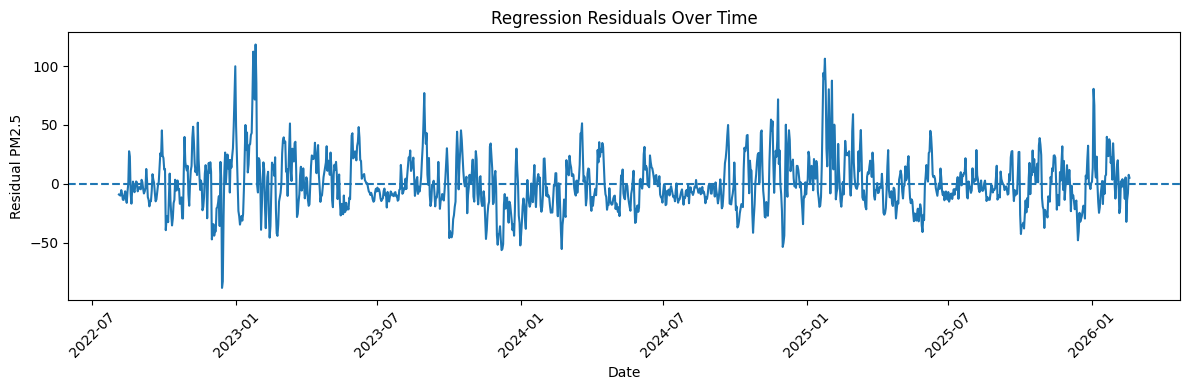

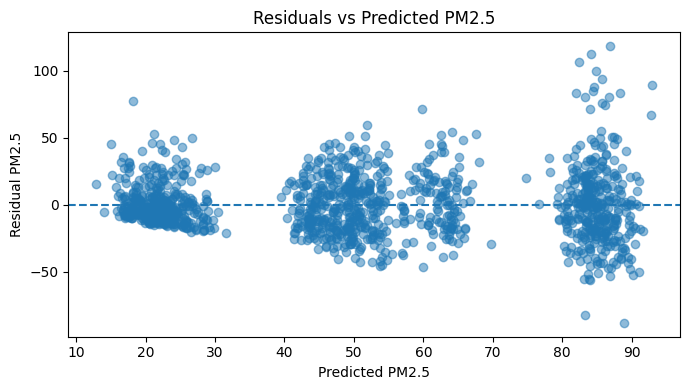

In [123]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.plot(model_data["date"], model.resid)
plt.axhline(0, linestyle="--")
plt.title("Regression Residuals Over Time")
plt.xlabel("Date")
plt.ylabel("Residual PM2.5")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


plt.figure(figsize=(7, 4))
plt.scatter(model.fittedvalues, model.resid, alpha=0.5)
plt.axhline(0, linestyle="--")
plt.title("Residuals vs Predicted PM2.5")
plt.xlabel("Predicted PM2.5")
plt.ylabel("Residual PM2.5")
plt.tight_layout()
plt.show()

In [124]:

from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
X = model_data[
    [
        "temperature_2m_mean",
        "relative_humidity_2m_mean",
        "precipitation_sum",
        "wind_speed_10m_mean",
        "surface_pressure_mean"
    ]
].copy()
vif_results = pd.DataFrame({
    "Variable": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
})

print(vif_results.sort_values("VIF", ascending=False).round(2))



                    Variable   VIF
4      surface_pressure_mean  3.12
0        temperature_2m_mean  3.09
1  relative_humidity_2m_mean  1.60
3        wind_speed_10m_mean  1.34
2          precipitation_sum  1.09


In [125]:

from statsmodels.stats.diagnostic import acorr_ljungbox

ljung_box_results = acorr_ljungbox(
    model.resid,
    lags=[7, 14],
    return_df=True
)

print(ljung_box_results)


        lb_stat      lb_pvalue
7   1416.760391  9.120381e-302
14  1430.434060  4.551333e-297
